# FairAsk - exploring the data

What is actually in the three datasets behind FairAsk, and what is missing from them.

Every number and chart here comes from running the loaders in this folder over the
real files. Nothing is simulated. Where a dataset cannot answer a question, the
chart says so rather than filling the gap.

| Source | Coverage | Rows |
|---|---|---|
| CREA MLS HPI | Jan 2005 to Sep 2026, 5 regions, monthly | 7,830 |
| Toronto sales | roughly 2019, no sale dates recorded | 14,892 |
| Brampton sales | Jan to May 2021 | 1,138 |

**The limitation that shapes everything below:** there is no Waterloo Region sold
data. The model learns price behaviour from Toronto and Brampton, two GTA markets,
and the HPI is what carries that to Waterloo Region. No accuracy claim about
Waterloo Region can be made from this data.

The raw files are gitignored (CREA is copyright, the two sales sets are
redistribution-restricted), so re-running this notebook needs
`python data/download.py` plus the manual CREA download described in
`data/SOURCES.md`.

In [1]:
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, ".")
from brampton import load_brampton
from hpi import load_hpi
from toronto import load_toronto

# Validated categorical slots (dataviz reference palette, light mode).
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
SURFACE, INK, INK_SOFT, RULE = "#fcfcfb", "#0b0b0b", "#52514e", "#dcdbd5"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": RULE, "axes.linewidth": 0.8, "axes.labelcolor": INK_SOFT,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "text.color": INK, "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": RULE, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 110,
})

hpi = load_hpi()
tor = load_toronto()
bra = load_brampton()
print(f"HPI      {len(hpi):,} rows   {hpi.month.min():%Y-%m} to {hpi.month.max():%Y-%m}")
print(f"Toronto  {len(tor):,} rows")
print(f"Brampton {len(bra):,} rows   {bra.sold_date.min():%Y-%m-%d} to {bra.sold_date.max():%Y-%m-%d}")

HPI      7,830 rows   2005-01 to 2026-09
Toronto  14,892 rows
Brampton 1,138 rows   2021-01-01 to 2021-05-21


## 1. What the benchmark price has done since 2005

This is the backbone of the whole valuation: FairAsk's fair value starts from the
CREA benchmark for a region, property type and month, then adjusts for how a
specific house differs from that benchmark.

Composite benchmark (all property types blended), not seasonally adjusted.

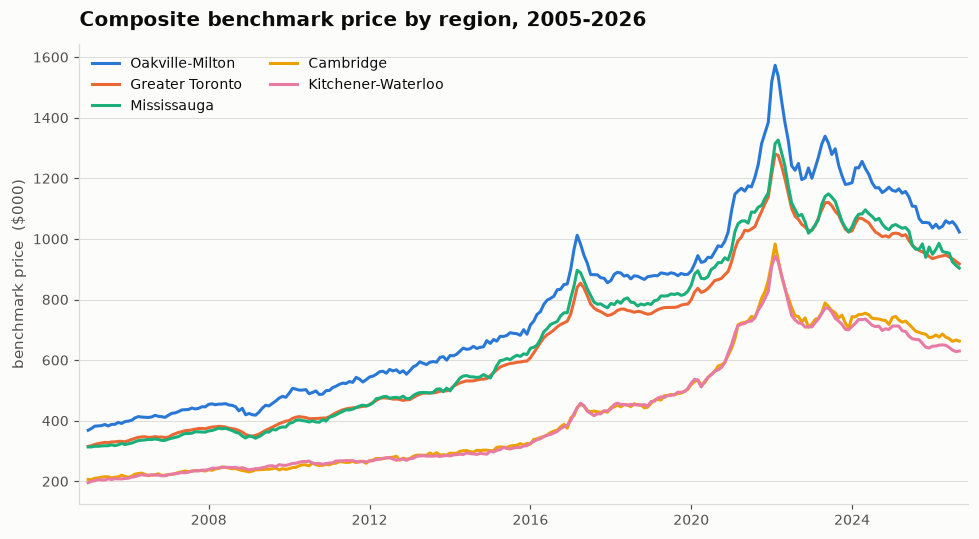

In [2]:
comp = hpi[hpi.property_type == "Composite"]
order = (comp[comp.month == comp.month.max()]
         .sort_values("benchmark_price", ascending=False)["region"].tolist())
colors = dict(zip(order, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))

fig, ax = plt.subplots(figsize=(9, 5))
for region in order:
    s = comp[comp.region == region]
    ax.plot(s.month, s.benchmark_price / 1000, color=colors[region], linewidth=2, label=region)

ax.set_title("Composite benchmark price by region, 2005-2026")
ax.set_ylabel("benchmark price  ($000)")
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.legend(loc="upper left", ncol=2)
ax.margins(x=0.01)
plt.tight_layout()
plt.show()

Three things worth noticing, because each one affects how the model has to work:

- **The 2022 peak and the correction after it.** Any sale from before 2022 has to be
  time-adjusted to today, or the model learns prices that no longer exist.
- **The regions are not parallel.** Oakville-Milton and Greater Toronto pulled away
  from Cambridge and Kitchener-Waterloo over the period, so one provincial index
  would misprice Waterloo Region badly.
- **The gap widened fastest during 2020-2022**, which is the window the training
  sales sit in or just before.

Three of these five series sit below 3:1 contrast on this surface, so the figures
are given as a table rather than relying on the line colour alone:

In [3]:
latest = (comp[comp.month == comp.month.max()]
          .set_index("region")["benchmark_price"]
          .reindex(order)
          .map("${:,.0f}".format)
          .rename(f"benchmark {comp.month.max():%b %Y}"))
latest.to_frame()

,benchmark Sep 2026
region,
Oakville-Milton,"$1,023,000"
Greater Toronto,"$917,600"
Mississauga,"$903,600"
Cambridge,"$662,700"
Kitchener-Waterloo,"$630,200"


## 2. What each dataset actually contains

The most important chart here. The two sales sources were collected by different
people for different purposes, and they do not have the same columns. A field at
0% is **absent from the source** - not zero, and not missing at random.

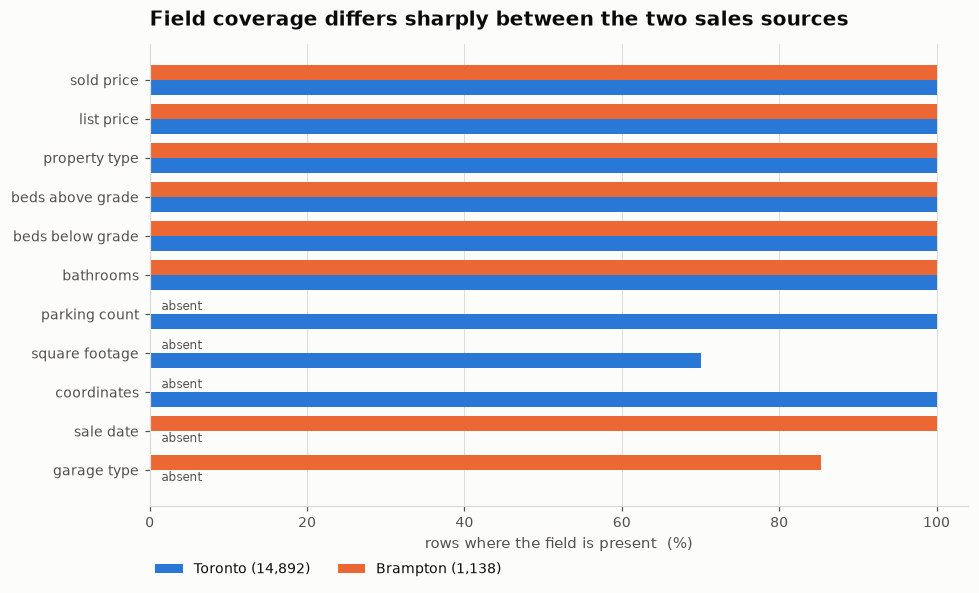

In [4]:
fields = {
    "sold price": ("sold_price", "sold_price"),
    "list price": ("list_price", "list_price"),
    "property type": ("property_type", "property_type"),
    "beds above grade": ("beds_above", "beds_above"),
    "beds below grade": ("beds_below", "beds_below"),
    "bathrooms": ("baths", "baths"),
    "parking count": ("parking", None),
    "square footage": ("sqft_mid", None),
    "coordinates": ("lat", None),
    "sale date": (None, "sold_date"),
    "garage type": (None, "garage_type"),
}


def coverage(df, column):
    if column is None or column not in df.columns:
        return 0.0
    return df[column].notna().mean() * 100


cov = pd.DataFrame(
    [(name, coverage(tor, t), coverage(bra, b)) for name, (t, b) in fields.items()],
    columns=["field", "Toronto", "Brampton"],
).set_index("field")

fig, ax = plt.subplots(figsize=(9, 5.5))
y = range(len(cov))
h = 0.38
ax.barh([i + h / 2 for i in y], cov["Toronto"], height=h, color=BLUE, label="Toronto (14,892)")
ax.barh([i - h / 2 for i in y], cov["Brampton"], height=h, color=ORANGE, label="Brampton (1,138)")

# Label only the absences - that is the story; the axis carries the rest.
for i, (t, b) in enumerate(zip(cov["Toronto"], cov["Brampton"])):
    if t == 0:
        ax.text(1.5, i + h / 2, "absent", va="center", fontsize=8, color=INK_SOFT)
    if b == 0:
        ax.text(1.5, i - h / 2, "absent", va="center", fontsize=8, color=INK_SOFT)

ax.set_yticks(list(y))
ax.set_yticklabels(cov.index)
ax.invert_yaxis()
ax.set_xlim(0, 104)
ax.set_xlabel("rows where the field is present  (%)")
ax.set_title("Field coverage differs sharply between the two sales sources")
ax.xaxis.grid(True)
ax.set_axisbelow(True)
# Below the axis: every row runs to 100%, so an in-plot legend would cover a bar.
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.11), ncol=2, borderaxespad=0)
plt.tight_layout()
plt.show()

The asymmetry is the finding:

- **Toronto has square footage, coordinates and a parking count, but no sale date.**
  Without a date, a Toronto sale cannot be time-adjusted precisely - only by
  assuming the dataset's stated vintage of roughly 2019.
- **Brampton has the sale date, but no square footage, no coordinates and no
  parking count** - only a garage type.
- **Square footage is missing for 29.9% of Toronto rows** even though the column
  exists, which is why Phase 2 plans a building-footprint estimate.

Training on the two sources combined means every feature one of them lacks has to
be handled deliberately. Filling those with zeros would teach the model that a
Brampton house has no floor area.

In [5]:
print(f"Toronto rows with no square footage: {tor['sqft_mid'].isna().sum():,} "
      f"of {len(tor):,} ({tor['sqft_mid'].isna().mean():.1%})")
print(f"Brampton rows with square footage:   0 of {len(bra):,} (0.0%) "
      f"- the column does not exist in the source")

Toronto rows with no square footage: 4,456 of 14,892 (29.9%)
Brampton rows with square footage:   0 of 1,138 (0.0%) - the column does not exist in the source


## 3. What we are trying to predict

Sold price by property type, Toronto. Log scale, because the range runs from about
$100k to $13M and a linear axis would compress everything under a million into one
band.

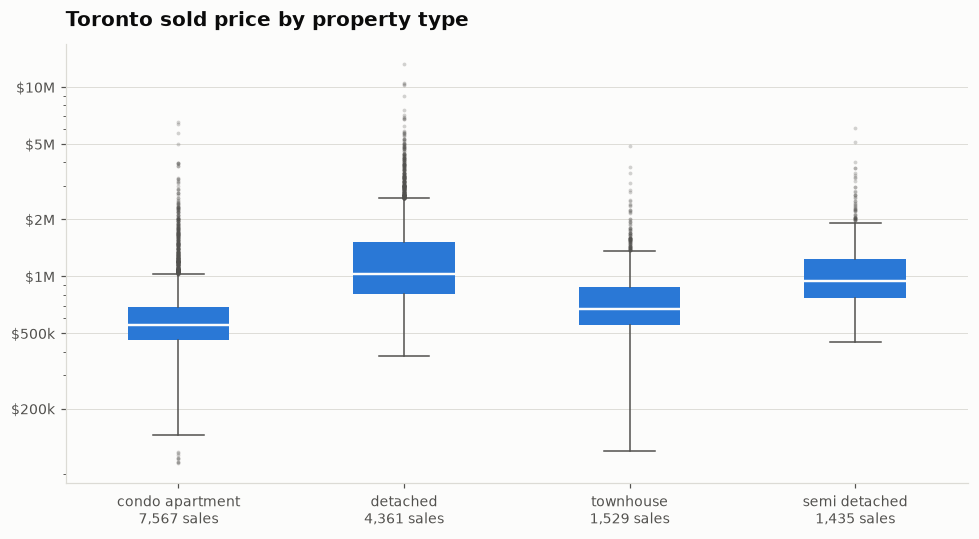

,sales,median,p10,p90
property_type,,,,
detached,4361,1025000,715000,2285000
semi_detached,1435,950000,695000,1509600
townhouse,1529,675000,464800,1200000
condo_apartment,7567,556500,390000,885046


In [6]:
types = tor.property_type.value_counts().index.tolist()
data = [tor.loc[tor.property_type == t, "sold_price"] for t in types]

fig, ax = plt.subplots(figsize=(9, 5))
bp = ax.boxplot(
    data, widths=0.45, patch_artist=True,
    medianprops=dict(color=SURFACE, linewidth=1.6),
    flierprops=dict(marker="o", markersize=2.5, markerfacecolor=INK_SOFT,
                    markeredgecolor="none", alpha=0.25),
)
for patch in bp["boxes"]:
    patch.set(facecolor=BLUE, edgecolor="none")
for part in ("whiskers", "caps"):
    for line in bp[part]:
        line.set(color=INK_SOFT, linewidth=1)

ax.set_yscale("log")
ax.set_yticks([200_000, 500_000, 1_000_000, 2_000_000, 5_000_000, 10_000_000])
ax.set_yticklabels(["$200k", "$500k", "$1M", "$2M", "$5M", "$10M"])
ax.set_xticklabels([f"{t.replace('_', ' ')}\n{len(d):,} sales" for t, d in zip(types, data)])
ax.set_title("Toronto sold price by property type")
ax.yaxis.grid(True)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

tor.groupby("property_type")["sold_price"].agg(
    sales="size",
    median="median",
    p10=lambda s: s.quantile(0.10),
    p90=lambda s: s.quantile(0.90),
).astype(int).sort_values("median", ascending=False)

Condo apartments and detached houses barely overlap across the middle of their
ranges. That is why property type cannot be a small correction bolted onto one
average price - it has to be part of the benchmark the house is compared against.

## 4. How hot the market was when each dataset was collected

Sold price divided by list price. Above 1.0 means homes went for over asking.

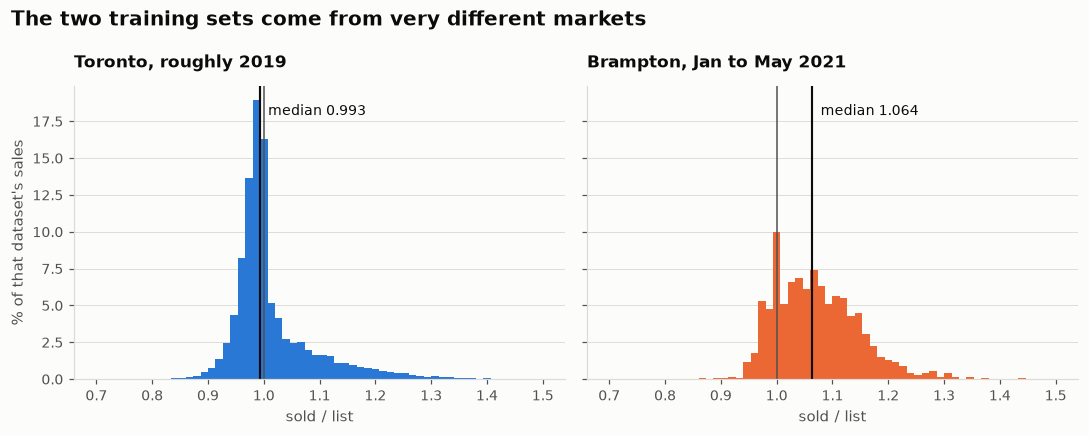

Toronto  median 0.993   sold over asking: 37.1%
Brampton median 1.064   sold over asking: 80.8%


In [7]:
tor_ratio = tor.sold_price / tor.list_price
bra_ratio = bra.sold_price / bra.list_price

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, (series, label, color) in zip(axes, [
    (tor_ratio, "Toronto, roughly 2019", BLUE),
    (bra_ratio, "Brampton, Jan to May 2021", ORANGE),
]):
    # Shown as a share of each dataset: Brampton has 1,138 sales against
    # Toronto's 14,892, so raw counts on a shared axis would flatten it to nothing.
    ax.hist(series, bins=60, range=(0.7, 1.5), color=color, edgecolor="none",
            weights=[100 / len(series)] * len(series))
    ax.axvline(1.0, color=INK_SOFT, linewidth=1)
    ax.axvline(series.median(), color=INK, linewidth=1.4)
    ax.text(series.median() + 0.015, ax.get_ylim()[1] * 0.9,
            f"median {series.median():.3f}", fontsize=9, color=INK)
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("sold / list")
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
axes[0].set_ylabel("% of that dataset's sales")
fig.suptitle("The two training sets come from very different markets",
             x=0.015, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

print(f"Toronto  median {tor_ratio.median():.3f}   sold over asking: {(tor_ratio > 1).mean():.1%}")
print(f"Brampton median {bra_ratio.median():.3f}   sold over asking: {(bra_ratio > 1).mean():.1%}")

This is a warning, not a feature. The two sources were collected two years apart in
very different conditions, so **list price must not be used as a model input** - it
carries the market temperature of its own moment, and the model would learn 2021
Brampton bidding behaviour as though it were a property characteristic.

It is also why sold prices have to be time-adjusted with the HPI before training,
rather than pooled as if a 2019 sale and a 2021 sale were comparable.

## 5. Price per square foot, where it can be measured

Only Toronto rows that have a square-footage bucket - about 70% of them. The bucket
midpoint is an approximation, because the source's ranges overlap (`1400-1599`,
`1100-1500` and `700-1100` all appear), so these figures carry real width and
should not be read to the dollar.

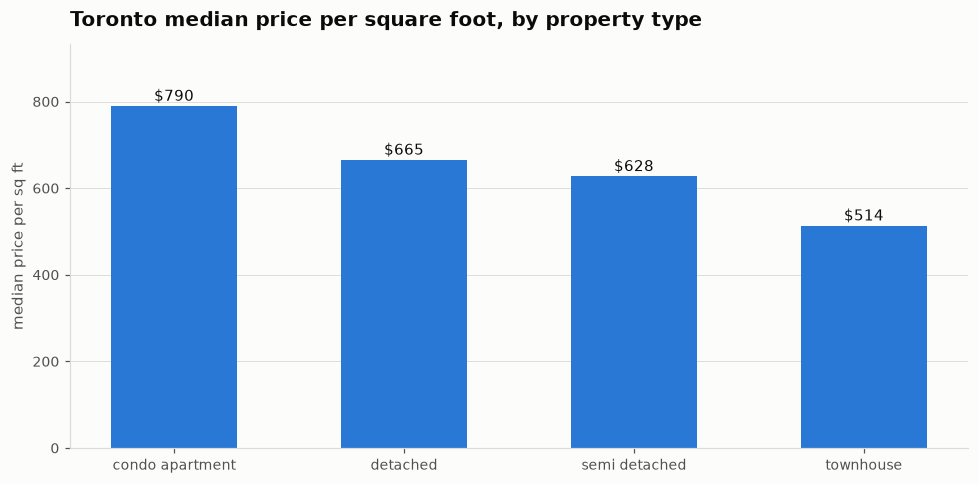

based on 10,436 of 14,892 Toronto sales (70.1%) that have a square-footage bucket


In [8]:
known = tor.dropna(subset=["sqft_mid"]).copy()
known["price_per_sqft"] = known.sold_price / known.sqft_mid
med = known.groupby("property_type")["price_per_sqft"].median().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(range(len(med)), med.values, width=0.55, color=BLUE)
for i, value in enumerate(med.values):
    ax.text(i, value + 12, f"${value:,.0f}", ha="center", fontsize=9.5, color=INK)
ax.set_xticks(range(len(med)))
ax.set_xticklabels([t.replace("_", " ") for t in med.index])
ax.set_ylabel("median price per sq ft")
ax.set_title("Toronto median price per square foot, by property type")
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.set_ylim(0, med.max() * 1.18)
plt.tight_layout()
plt.show()

print(f"based on {len(known):,} of {len(tor):,} Toronto sales "
      f"({len(known) / len(tor):.1%}) that have a square-footage bucket")

Condo apartments come out highest at about $790/sq ft and townhouses lowest at
about $514, with detached in between at $665 - **not** at the bottom, which is
worth pausing on. A detached buyer is also paying for land, and square footage
does not measure land at all. What pulls detached below condos is size: price per
square foot falls as homes get larger, so the biggest homes look cheapest by this
measure while costing the most.

That is exactly why price per square foot is a poor valuation tool on its own, and
why the model uses it as one feature among many rather than as the method.

## What this means for the build

1. **Time-adjust every sale with the HPI before training.** The 2022 peak makes raw
   historical prices misleading, and the two sources sit in different markets.
2. **Never feed list price to the model.** Section 4 shows it encodes the market
   temperature of its collection date.
3. **Handle the Toronto/Brampton column asymmetry explicitly.** Section 2 shows each
   source lacks what the other has; zero-filling would be a lie.
4. **Square footage needs a fallback.** 29.9% of Toronto rows lack it and Brampton
   has none at all, which is what the Phase 2 footprint estimate is for.
5. **No Waterloo Region accuracy claim is possible yet.** Nothing in this notebook
   is a Waterloo Region sale.